# Szereg czasowy sprzedaży sklepu: ARIMA w praktyce
Analiza dziennej sprzedaży całego sklepu krok po kroku według wpisu [„Szeregi czasowe: ARIMA w praktyce” (metodolog.pl)](https://www.metodolog.pl/blog/szeregi-czasowe-arima-w-praktyce/). Artykuł pracuje w R na szeregu miesięcznym. Tu te same kroki są w Pythonie (`statsmodels`) na szeregu dziennym.

**Zakres:** lata 2023 i 2024. Rok 2025 to rok testowy, więc nie wchodzi do analizy. Ostatnie 8 tygodni 2024 (od 2024-11-04) służą do sprawdzenia prognozy (krok 5), a model jest dopasowany tylko na wcześniejszych dniach.

| Krok w artykule | Tutaj | Co zmienione i dlaczego |
|---|---|---|
| Przygotowanie: równe odstępy | sekcja 0 | Szereg dzienny z **każdym** dniem kalendarza. Dni zamknięte mają sprzedaż 0 i flagę `zamkniety`, żeby odstępy były równe. |
| 1. Trend i sezonowość, `decompose()` | sekcja 1 | Okres sezonowy 7 dni (tydzień) zamiast 12 miesięcy. Sezon roczny modelujemy miesiącami, jak w artykule. |
| 2. ACF, PACF, Ljung–Box, różnicowanie sezonowe | sekcja 2 | Ljung–Box na 28 opóźnieniach (4 tygodnie) zamiast 24 miesięcy. Dodatkowo, poza artykułem: testy ADF i KPSS. |
| 3. SARIMA, potem regresja z błędami ARMA, AIC/BIC, `auto.arima()` | sekcja 3 | SARIMA(1,0,0)(0,1,1)₇. W regresji: trend, dni tygodnia, miesiące i dni świąteczne. Zamiast `auto.arima()` przeszukujemy siatkę rzędów wg AIC. |
| 4. Diagnostyka reszt | sekcja 4 | Bez zmian (Ljung–Box z `model_df` = liczba parametrów ARMA, współczynniki z błędami standardowymi). |
| 5. Prognoza i przedział 95 % | sekcja 5 | Prognoza 8 tygodni naprzód z przedziałem. Dodatkowo: prognoza kroczącą na tydzień naprzód i porównanie z `Tydzien_temu` i `Srednia_4_tygodni`. |
| 6. Przerwany szereg czasowy | pominięty | Wymaga z góry ustalonej daty zmiany (interwencji), np. remontu albo zmiany godzin otwarcia. Bez takiej daty ten krok nie ma sensu. |
| 7. Raportowanie | sekcja 6 | Podsumowanie liczone automatycznie. |

**Notatnik samodzielny:** wczytuje dane z `dane/interim/fact_inka_final_stan_dzienny.parquet` i nie korzysta ze zmiennych z innych notatników.

## Jak korzystać z tego notatnika (wersja z objaśnieniami)
Przed każdą komórką z kodem jest komórka **„Objaśnienie”**: po co jest komórka, jakie pojęcia wprowadza, co robi kod i jak czytać wynik. Objaśnienia nie podają liczb z danych; odczytasz je z wyników po uruchomieniu. Komórki uruchamiaj od góry do dołu. Przeszukiwanie siatki modeli (sekcja 3) trwa kilka minut.

### Słowniczek
| Pojęcie | Znaczenie |
|---|---|
| **Szereg czasowy** | Ta sama wielkość mierzona w równych odstępach czasu (tu: sprzedaż każdego dnia). Kolejność obserwacji ma znaczenie. |
| **Stacjonarność** | Szereg ma stałą średnią i zmienność w czasie, a zależność między dniami zależy tylko od odległości między nimi. Trend i sezonowość łamią stacjonarność. |
| **Różnicowanie** | Zastąpienie wartości różnicą względem wartości wcześniejszej. Różnicowanie sezonowe z opóźnieniem 7: dzień minus ten sam dzień tydzień wcześniej. |
| **ACF** | Funkcja autokorelacji: korelacja szeregu z nim samym przesuniętym o k dni. |
| **PACF** | Częściowa autokorelacja: korelacja przy opóźnieniu k po usunięciu wpływu opóźnień krótszych. |
| **Test Ljunga–Boxa** | Sprawdza, czy autokorelacje do zadanego opóźnienia są łącznie równe zero. p > 0,05: brak dowodu zależności (dla reszt: dobrze). |
| **AR(p)** | Część autoregresyjna: wartość zależy od p poprzednich wartości (u nas: poprzednich błędów regresji). |
| **MA(q)** | Średnia ruchoma: wartość zależy od q poprzednich zaskoczeń (błędów prognozy o krok). |
| **ARIMA(p,d,q)(P,D,Q)ₛ** | Model z częścią AR, różnicowaniem d, częścią MA oraz ich sezonowymi odpowiednikami o okresie s (tu s = 7). |
| **Regresja z błędami ARMA** | Regresja (trend, dni tygodnia, miesiące, święta), w której błędy nie są niezależne, tylko tworzą proces ARMA. Tak artykuł modeluje sezonowość zamiast różnicowania. |
| **Zmienna zero-jedynkowa** | Kolumna 1/0, np. „czy to wtorek”. Jedna kategoria (poniedziałek, styczeń) jest pominięta i stanowi punkt odniesienia. |
| **AIC / BIC** | Kryteria informacyjne: mniejsze = lepszy kompromis między dopasowaniem a liczbą parametrów. ΔAIC to różnica względem najlepszego modelu. |
| **Przedział predykcji 95 %** | Przedział, w którym przy poprawnym modelu powinno leżeć ok. 95 % przyszłych obserwacji. |
| **WAPE** | Suma błędów bezwzględnych / suma sprzedaży × 100 %. |

#### Objaśnienie: przygotowanie środowiska
**Po co ta komórka.** Wczytujemy biblioteki i ustalamy wygląd wykresów. Komórka nie daje wyniku.

**Biblioteki.**
- `statsmodels` to główna biblioteka do szeregów czasowych w Pythonie, odpowiednik funkcji z pakietu `stats` w R używanych w artykule: `seasonal_decompose` ≈ `decompose()`, `plot_acf`/`plot_pacf` ≈ `acf()`/`pacf()`, `acorr_ljungbox` ≈ `Box.test()`, `SARIMAX` ≈ `arima()` z argumentem `xreg`, `OLS` ≈ `lm()`.
- `adfuller` i `kpss` to testy stacjonarności (w artykule ich nie ma).

**Co robi kod.**
- `warnings.filterwarnings(...)` wycisza ostrzeżenia o zbieżności optymalizatora, które `SARIMAX` zgłasza bardzo często przy przeszukiwaniu siatki modeli. Wyniki sprawdzamy i tak diagnostyką.
- `WALID_OD` to pierwszy dzień okresu sprawdzającego (poniedziałek 2024-11-04). Model nie widzi dni od tej daty.

In [1]:
import os
import warnings
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from dateutil.easter import easter
import statsmodels.api as sm
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import adfuller, kpss, acf
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore", module="statsmodels")
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
from statsmodels.tools.sm_exceptions import InterpolationWarning
warnings.filterwarnings("ignore", category=InterpolationWarning)   # KPSS: p-wartość poza tablicą (0,01-0,10)

if os.path.basename(os.getcwd()) != "analiza_sprzedazy_w_sklepie":
    os.chdir("../..")

NIEB, POM, MOR, SZARY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a85"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "font.size": 10,
})

POCZ, KONIEC = pd.Timestamp("2023-01-01"), pd.Timestamp("2024-12-31")   # 2025 = rok testowy, poza analizą
WALID_OD = pd.Timestamp("2024-11-04")                                    # 8 tygodni na sprawdzenie prognozy
S = 7                                                                    # okres sezonowy: tydzień
LAGI_LB = 28                                                             # Ljung-Box: 4 tygodnie
DNI_TYG = ["Pn", "Wt", "Śr", "Cz", "Pt", "So", "Nd"]

## 0. Przygotowanie danych: szereg o równych odstępach
Artykuł zaczyna od sprawdzenia, że dane to szereg czasowy: ta sama wielkość w **równych odstępach**. Sklep ma dni zamknięte (niedziele, święta). Gdybyśmy je usunęli, sąsiednimi obserwacjami byłyby np. sobota i poniedziałek, a „opóźnienie 7” nie oznaczałoby już tygodnia. Dlatego zostawiamy każdy dzień kalendarza: dzień zamknięty ma sprzedaż 0 i flagę `zamkniety = 1` w części regresyjnej, która tę zerową sprzedaż wyjaśnia.

#### Objaśnienie: szereg dzienny i regresory
**Po co ta komórka.** Budujemy dwie rzeczy: szereg `y` (sprzedaż dzienna sklepu w tys. zł) i tabelę `X` z regresorami, czyli zmiennymi znanymi z góry, które trafią do części regresyjnej modelu.

**Pojęcia.**
- **Regresor** (w R: `xreg`) to zmienna objaśniająca podana modelowi z zewnątrz. Wszystkie regresory tutaj wynikają z kalendarza, więc są znane także dla przyszłych dni.
- **Punkt odniesienia zmiennych zero-jedynkowych**: poniedziałek i styczeń nie mają kolumn. Współczynnik przy `dt_Wt` mówi, o ile wtorek różni się od poniedziałku. Gdyby były kolumny dla wszystkich 7 dni i stała, model nie dałby się oszacować (kolumny sumowałyby się do stałej).

**Co robi kod.**
- `kal_pq` to kalendarz z pliku, jeden wiersz na dzień, z kontrolą jednoznaczności (jak w notatniku głównym).
- `sprzedaz` to pozycje sprzedaży (`TypDok == 21`, bez pustych dni `DokId == -1`).
- `y` to suma dzienna w **tys. zł**. Mniejsze liczby ułatwiają optymalizację modelu i nie zmieniają wniosków.
- Dzień bez wiersza w kalendarzu pliku i bez sprzedaży traktujemy jako zamknięty (tak jak w notatniku głównym 1 stycznia).
- Regresory w `X`:
  - `const` (stała) i `t` (czas w latach od 1.01.2023): liniowy trend, tak jak w artykule;
  - `dt_Wt` … `dt_Nd`: dni tygodnia; `m_02` … `m_12`: miesiące (artykuł: 11 zmiennych miesięcy);
  - `zamkniety`: dzień zamknięty;
  - `przed_swietem`: dzień otwarty przed dniem zamkniętym, który nie jest niedzielą (zakupy przed świętem);
  - `tydz_przed_wlk`: 6 dni przed Wielkanocą (Wielkanoc co roku wypada w innym miejscu, więc miesiące jej nie uchwycą);
  - `przed_bn`: 18–24 grudnia (zakupy przed Bożym Narodzeniem).

**Jak czytać wynik.** Liczba dni otwartych i zamkniętych oraz kontrola: dni otwarte z zerową sprzedażą (powinno ich być 0 albo bardzo mało; jeśli jest dużo, flaga dni zamkniętych w pliku nie zgadza się ze sprzedażą).

In [2]:
PLIK = "dane/interim/fact_inka_final_stan_dzienny.parquet"
kal_pq = pd.read_parquet(PLIK, columns=["Data", "CzyZamkniety"]).drop_duplicates()
assert kal_pq["Data"].is_unique, "kalendarz w pliku nie jest jednoznaczny (różne flagi dla tej samej daty)"

sprzedaz = pd.read_parquet(PLIK, columns=["Data", "DokId", "TypDok", "Wartosc"])
sprzedaz = sprzedaz[(sprzedaz["DokId"] != -1) & (sprzedaz["TypDok"] == 21)]

dni = pd.date_range(POCZ, KONIEC, freq="D")
y = sprzedaz.groupby("Data")["Wartosc"].sum().reindex(dni, fill_value=0) / 1000      # tys. zł
y.index.name = "Data"; y.index.freq = "D"
zamk = kal_pq.set_index("Data")["CzyZamkniety"].reindex(dni)
zamk = zamk.fillna((y == 0).astype(int)).astype(int)        # brak w kalendarzu i brak sprzedaży = zamknięty
del kal_pq

def regresory(dni, zamk):
    X = pd.DataFrame(index=dni)
    X["const"] = 1.0
    X["t"] = np.arange(len(dni)) / 365.25
    for d in range(1, 7):
        X[f"dt_{DNI_TYG[d]}"] = (dni.dayofweek == d).astype(float)
    for m in range(2, 13):
        X[f"m_{m:02d}"] = (dni.month == m).astype(float)
    z = zamk.reindex(dni).astype(float)
    X["zamkniety"] = z
    jutro_zamk = z.shift(-1).fillna(0) == 1
    jutro_nd = (dni + pd.Timedelta(days=1)).dayofweek == 6
    X["przed_swietem"] = (jutro_zamk & ~jutro_nd & (z == 0)).astype(float)
    wlk = pd.DatetimeIndex([pd.Timestamp(easter(r)) for r in sorted(set(dni.year))])
    przed_wlk = set(d - pd.Timedelta(days=k) for d in wlk for k in range(1, 7))
    X["tydz_przed_wlk"] = (dni.isin(list(przed_wlk)) & (z.values == 0)).astype(float)
    X["przed_bn"] = ((dni.month == 12) & (dni.day >= 18) & (dni.day <= 24) & (z.values == 0)).astype(float)
    return X

X = regresory(dni, zamk)
X = X.loc[:, X.loc[:WALID_OD - pd.Timedelta(days=1)].std().gt(0) | (X.columns == "const")]   # bez kolumn stałych w okresie uczącym
uczacy = dni < WALID_OD
y_u, X_u = y[uczacy], X[uczacy]
y_w, X_w = y[~uczacy], X[~uczacy]

print(f"Dni: {len(y)} ({y.index.min().date()} … {y.index.max().date()}) | otwarte: {int((zamk == 0).sum())} | zamknięte: {int(zamk.sum())}")
print(f"Okres uczący: {len(y_u)} dni (do {y_u.index.max().date()}) | sprawdzający: {len(y_w)} dni (od {y_w.index.min().date()})")
print(f"Kontrola: dni otwarte z zerową sprzedażą: {int(((zamk == 0) & (y == 0)).sum())}, sprzedaż w dni zamknięte: {y[zamk == 1].sum():.2f} tys. zł")
print("Regresory:", list(X.columns))

Dni: 731 (2023-01-01 … 2024-12-31) | otwarte: 617 | zamknięte: 114
Okres uczący: 673 dni (do 2024-11-03) | sprawdzający: 58 dni (od 2024-11-04)
Kontrola: dni otwarte z zerową sprzedażą: 0, sprzedaż w dni zamknięte: 0.00 tys. zł
Regresory: ['const', 't', 'dt_Wt', 'dt_Śr', 'dt_Cz', 'dt_Pt', 'dt_So', 'dt_Nd', 'm_02', 'm_03', 'm_04', 'm_05', 'm_06', 'm_07', 'm_08', 'm_09', 'm_10', 'm_11', 'm_12', 'zamkniety', 'przed_swietem', 'tydz_przed_wlk', 'przed_bn']


## 1. Trend i sezonowość
Artykuł: narysuj szereg, wykonaj klasyczną dekompozycję addytywną i odczytaj efekty sezonowe. Jeśli profil sezonowy jest stały z roku na rok, modeluj go zmiennymi zero-jedynkowymi, a nie różnicowaniem.

#### Objaśnienie: wykres szeregu i dekompozycja
**Po co ta komórka.** Zanim zbudujemy model, patrzymy, z czego składa się szereg: czy ma trend, jaki jest rytm tygodnia i ile zostaje „szumu”.

**Pojęcia.**
- **Dekompozycja addytywna**: szereg = trend + sezonowość + reszta. Addytywna oznacza, że efekty się dodają (np. sobota daje +X zł niezależnie od poziomu sprzedaży).
- **Trend z dekompozycji klasycznej** to scentrowana średnia ruchoma o długości okresu. W artykule 2 × 12 dla miesięcy; tu 7 dni (okres nieparzysty nie wymaga podwójnej średniej).
- **Efekt sezonowy dnia tygodnia**: średnie odchylenie danego dnia tygodnia od trendu.

**Co robi kod.**
- Górny wykres: cały szereg 2023–2024 z zaznaczonym okresem sprawdzającym.
- `seasonal_decompose(..., period=7)` na okresie uczącym. Klasyczna dekompozycja nie przyjmuje braków ani nie rozumie dni zamkniętych, więc **tylko na potrzeby dekompozycji** dni zamknięte zastępujemy interpolacją z sąsiednich dni otwartych. Bez tego niedziele i święta (sprzedaż 0) zdominowałyby efekt sezonowy.
- `efekty` to efekt sezonowy każdego dnia tygodnia w tys. zł.

**Jak czytać wynik.**
- Panel „trend”: wyraźne wznoszenie albo opadanie oznacza trend, który trzeba uwzględnić (w regresji jest `t`).
- Panel „sezonowość”: powtarzający się wzór tygodnia. Tabela efektów mówi, które dni są najmocniejsze.
- Panel „reszta”: pojedyncze skoki to zwykle dni świąteczne i okolice świąt. Uwzględniamy je regresorami (`przed_swietem`, `tydz_przed_wlk`, `przed_bn`).

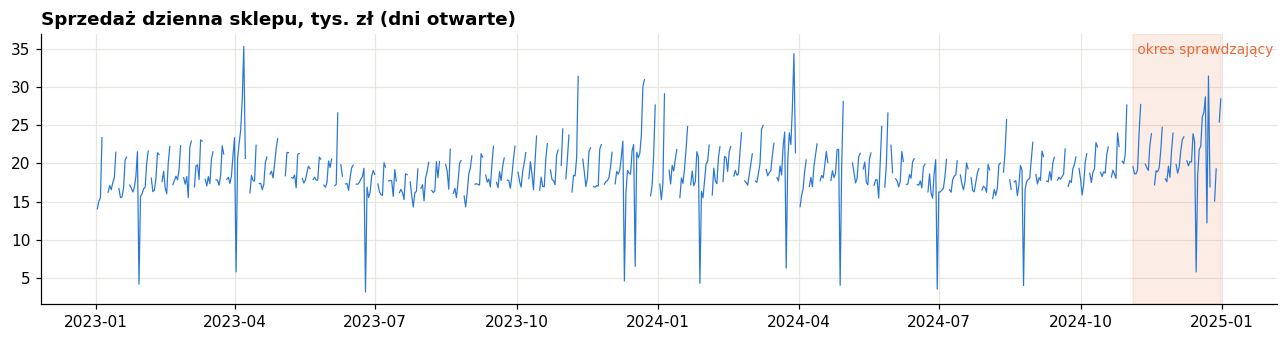

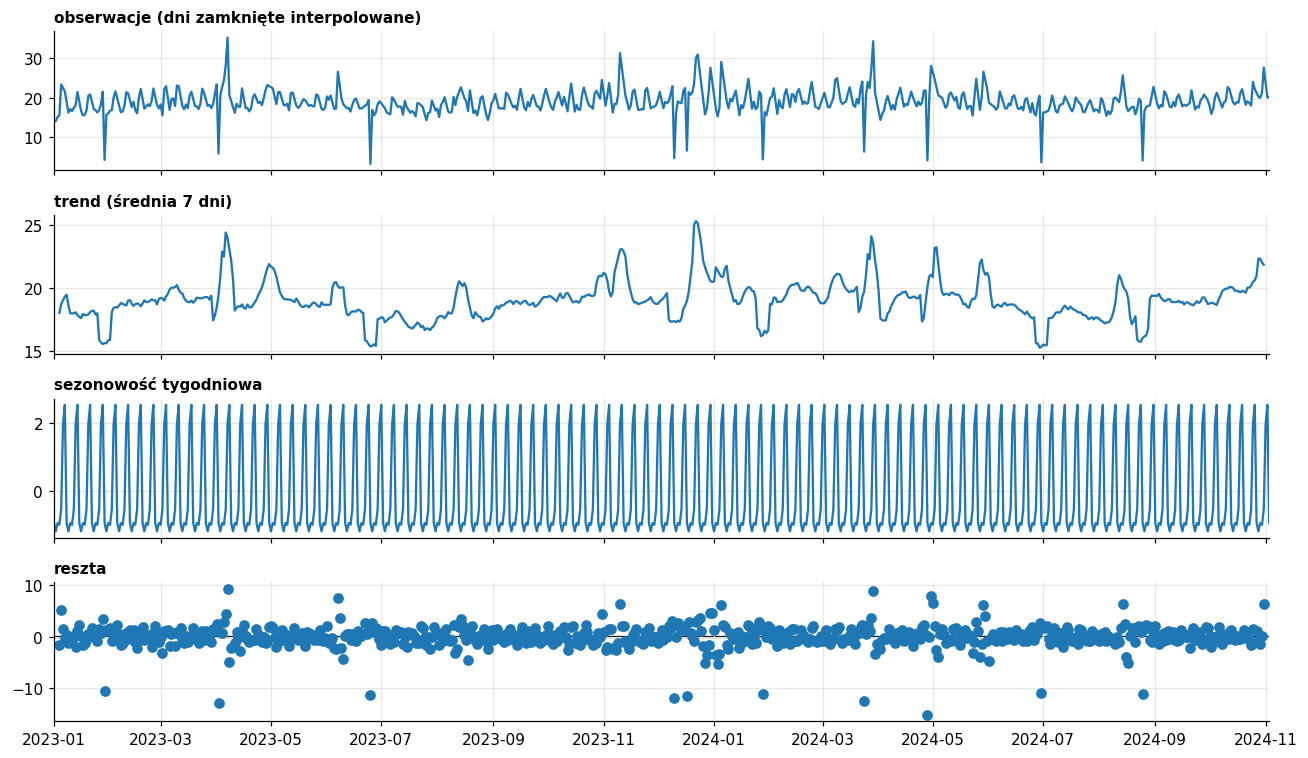

Efekt sezonowy dnia tygodnia (tys. zł względem trendu):
Data
Pn   -1.16
Wt   -0.92
Śr   -0.97
Cz   -0.52
Pt    1.96
So    2.52
Nd   -0.92


In [3]:
fig, ax = plt.subplots(figsize=(12, 3.2))
ax.plot(y.index, y.where(zamk == 0), color=NIEB, lw=0.8)
ax.axvspan(WALID_OD, KONIEC, color=POM, alpha=0.12)
ax.text(WALID_OD, ax.get_ylim()[1] * 0.97, " okres sprawdzający", color=POM, va="top", fontsize=9)
ax.set_title("Sprzedaż dzienna sklepu, tys. zł (dni otwarte)")
plt.tight_layout(); plt.show()

y_dek = y_u.where(zamk[uczacy] == 0).interpolate(limit_direction="both")   # tylko do dekompozycji
dek = seasonal_decompose(y_dek, model="additive", period=S)
fig = dek.plot(); fig.set_size_inches(12, 7)
for a, t in zip(fig.axes, ["obserwacje (dni zamknięte interpolowane)", "trend (średnia 7 dni)", "sezonowość tygodniowa", "reszta"]):
    a.set_title(t, fontsize=10, loc="left"); a.set_ylabel("")
plt.tight_layout(); plt.show()

efekty = dek.seasonal.groupby(dek.seasonal.index.dayofweek).first().rename(index=dict(enumerate(DNI_TYG)))
print("Efekt sezonowy dnia tygodnia (tys. zł względem trendu):")
print(efekty.round(2).to_string())

#### Objaśnienie: czy profil sezonowy jest stały z roku na rok
**Po co ta komórka.** To warunek z artykułu: zmienne zero-jedynkowe (jeden współczynnik na wtorek, jeden na grudzień) mają sens tylko wtedy, gdy profil sezonowy się nie zmienia. Jeśli się zmienia, lepsze jest różnicowanie sezonowe, które „uczy się” profilu na bieżąco.

**Co robi kod.**
- `profil_dt`: średnia sprzedaż na dzień otwarty w każdym dniu tygodnia, osobno dla 2023 i okresu uczącego 2024, jako indeks (1,00 = średni dzień otwarty roku). Indeks usuwa różnicę poziomu między latami.
- `profil_m`: to samo dla miesięcy (2024 tylko do października, bo listopad i grudzień są w okresie sprawdzającym).
- Kolumna `różnica` to 2024 minus 2023.

**Jak czytać wynik.** Różnice indeksów rzędu kilku setnych oznaczają stały profil, więc zmienne zero-jedynkowe są właściwe. Duże różnice w pojedynczych miesiącach (np. kwiecień, marzec) to zwykle przesunięcie Wielkanocy, które wyjaśnia `tydz_przed_wlk`.

In [4]:
otw = y_u[zamk[uczacy] == 0]
profil_dt = otw.groupby([otw.index.year, otw.index.dayofweek]).mean().unstack(0)
profil_dt = (profil_dt / profil_dt.mean()).rename(index=dict(enumerate(DNI_TYG)))
profil_dt["różnica"] = profil_dt[2024] - profil_dt[2023]
profil_m = otw.groupby([otw.index.year, otw.index.month]).mean().unstack(0)
profil_m = profil_m / profil_m.loc[1:10].mean()                  # wspólne miesiące 1-10 jako baza obu lat
profil_m["różnica"] = profil_m[2024] - profil_m[2023]
print("Profil dnia tygodnia (indeks, 1,00 = średni dzień otwarty roku):")
print(profil_dt.round(3).to_string())
print("\nProfil miesięcy (indeks, 1,00 = średni dzień otwarty w miesiącach 1-10):")
print(profil_m.round(3).to_string())

Profil dnia tygodnia (indeks, 1,00 = średni dzień otwarty roku):
Data   2023   2024  różnica
Data                       
Pn    1.042  1.040   -0.002
Wt    1.051  1.072    0.021
Śr    1.043  1.065    0.022
Cz    1.075  1.087    0.012
Pt    1.229  1.235    0.006
So    1.274  1.243   -0.031
Nd    0.287  0.259   -0.028

Profil miesięcy (indeks, 1,00 = średni dzień otwarty w miesiącach 1-10):
Data   2023   2024  różnica
Data                       
1     0.925  0.975    0.051
2     1.004  1.031    0.027
3     1.039  1.095    0.056
4     1.088  0.987   -0.101
5     1.022  1.048    0.027
6     0.965  0.934   -0.031
7     0.928  0.935    0.007
8     0.972  0.947   -0.025
9     1.016  0.995   -0.021
10    1.042  1.053    0.011
11    1.054  1.058    0.004
12    1.073    NaN      NaN


## 2. Autokorelacja i stacjonarność
Artykuł: policz ACF i PACF (granice ±1,96/√n), zrób test Ljunga–Boxa, a po różnicowaniu sezonowym sprawdź, czy przy opóźnieniu sezonowym nie pojawia się silna ujemna autokorelacja (sygnał zbyt silnego różnicowania).

#### Objaśnienie: ACF, PACF i test Ljunga–Boxa
**Po co ta komórka.** Sprawdzamy, czy sprzedaż z jednego dnia mówi coś o sprzedaży kolejnych dni. Jeśli tak, zwykła regresja z niezależnymi błędami jest niewłaściwa, a ARIMA ma co modelować.

**Pojęcia.**
- **Granice istotności** ±1,96/√n: przy n dniach autokorelacja poza tym pasem jest istotna na poziomie 5 % (przy założeniu, że szereg to biały szum).
- **Biały szum**: szereg bez żadnej zależności między obserwacjami; najlepsze, czego można chcieć od reszt modelu.

**Co robi kod.**
- `plot_acf` i `plot_pacf` dla 28 opóźnień na okresie uczącym, na surowym szeregu (z zerami w dni zamknięte, bo taki szereg modelujemy).
- `acorr_ljungbox(..., lags=[28])` to test łączny dla opóźnień 1–28.

**Jak czytać wynik.** Wysokie słupki ACF przy 7, 14, 21, 28 to rytm tygodnia. Powolne wygasanie ACF oznacza trend albo zmiany poziomu. PACF z wyraźnym słupkiem przy 1 (i może 2) sugeruje część AR. p-wartość Ljunga–Boxa bliska 0 potwierdza zależność.

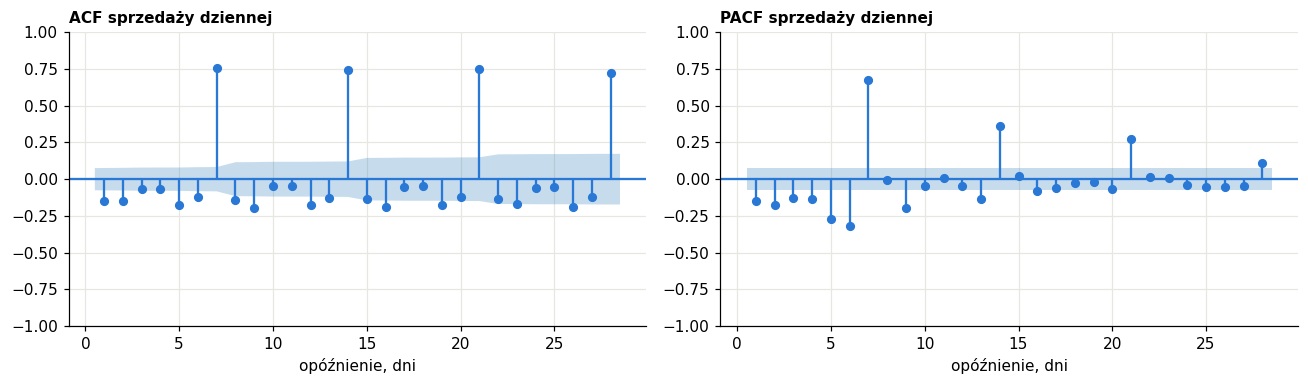

n = 673, granice ACF ±1,96/√n = ±0.076
Ljung-Box (28 opóźnień): Q = 1816.9, p = 0.0000


In [5]:
n_u = len(y_u)
gr = 1.96 / np.sqrt(n_u)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
plot_acf(y_u, lags=LAGI_LB, ax=axs[0], zero=False, color=NIEB, vlines_kwargs={"colors": NIEB})
plot_pacf(y_u, lags=LAGI_LB, ax=axs[1], zero=False, method="ywm", color=NIEB, vlines_kwargs={"colors": NIEB})
axs[0].set_title("ACF sprzedaży dziennej", fontsize=10); axs[1].set_title("PACF sprzedaży dziennej", fontsize=10)
for a in axs: a.set_xlabel("opóźnienie, dni")
plt.tight_layout(); plt.show()
lb = acorr_ljungbox(y_u, lags=[LAGI_LB])
print(f"n = {n_u}, granice ACF ±1,96/√n = ±{gr:.3f}")
print(f"Ljung-Box ({LAGI_LB} opóźnień): Q = {lb['lb_stat'].iloc[0]:.1f}, p = {lb['lb_pvalue'].iloc[0]:.4f}")

#### Objaśnienie: testy stacjonarności ADF i KPSS (dodatkowo, poza artykułem)
**Po co ta komórka.** Artykuł ocenia stacjonarność „na oko” (szereg z trendem nie jest stacjonarny). Dwa testy formalne dają to samo w liczbach i sprawdzają się nawzajem, bo mają odwrotne hipotezy.

**Pojęcia.**
- **ADF** (Augmented Dickey–Fuller). Hipoteza zerowa: szereg ma pierwiastek jednostkowy (nie jest stacjonarny). p < 0,05: odrzucamy, więc szereg jest stacjonarny.
- **KPSS**. Hipoteza zerowa: szereg jest stacjonarny (wokół trendu, gdy `regression="ct"`). p < 0,05: odrzucamy, więc szereg nie jest stacjonarny.
- **Stacjonarność wokół trendu**: po odjęciu linii trendu szereg jest stacjonarny. Wtedy wystarczy trend w regresji i różnicowanie zwykłe (d = 1) nie jest potrzebne.

**Co robi kod.** Oba testy z trendem (`"ct"`) na surowym szeregu oraz na resztach regresji z dniami tygodnia, miesiącami i świętami (czyli po usunięciu tego, co model wyjaśni regresorami). KPSS podaje p-wartości tylko w przedziale 0,01–0,10; wartość na granicy oznacza „co najmniej tyle”.

**Jak czytać wynik.**
- ADF p < 0,05 i KPSS p > 0,05: stacjonarny wokół trendu. Wtedy d = 0, jak w części regresyjnej artykułu.
- Oba odrzucają albo oba nie odrzucają: wynik niejednoznaczny. Decyduje diagnostyka modelu (sekcja 4).

In [6]:
ols0 = sm.OLS(y_u, X_u).fit()
wiersze = []
for nazwa, s_ in [("surowy szereg", y_u), ("reszty regresji (bez ARMA)", ols0.resid)]:
    adf_p = adfuller(s_, regression="ct", autolag="AIC")[1]
    kpss_p = kpss(s_, regression="ct", nlags="auto")[1]
    wiersze.append({"szereg": nazwa, "ADF_p": adf_p, "KPSS_p": kpss_p,
                    "wniosek": "stacjonarny wokół trendu" if (adf_p < 0.05 and kpss_p > 0.05)
                    else ("niestacjonarny" if (adf_p >= 0.05 and kpss_p <= 0.05) else "niejednoznaczny")})
print(pd.DataFrame(wiersze).round(4).to_string(index=False))

                    szereg  ADF_p  KPSS_p                  wniosek
             surowy szereg 0.0026     0.1 stacjonarny wokół trendu
reszty regresji (bez ARMA) 0.0000     0.1 stacjonarny wokół trendu


#### Objaśnienie: różnicowanie sezonowe i sygnał zbyt silnego różnicowania
**Po co ta komórka.** Artykuł pokazuje alternatywę dla zmiennych zero-jedynkowych: różnicowanie sezonowe. Tu: dzień minus ten sam dzień tydzień wcześniej. Usuwa ono rytm tygodnia, ale może „przesadzić”.

**Pojęcia.**
- **Zbyt silne różnicowanie**: gdy szereg był już (prawie) stacjonarny, różnicowanie wprowadza sztuczną ujemną autokorelację. Teoretycznie dla różnicy białego szumu ACF przy opóźnieniu sezonowym wynosi −0,5. W artykule wartość −0,447 przy opóźnieniu 12 była właśnie takim sygnałem.

**Co robi kod.** `y_u.diff(7)` liczy różnice tygodniowe, rysuje ich ACF i wypisuje autokorelację przy opóźnieniu 7.

**Jak czytać wynik.** Autokorelacja przy 7 bliska −0,5 (np. poniżej −0,35) oznacza, że różnicowanie sezonowe jest prawdopodobnie zbędne i lepiej modelować tydzień zmiennymi zero-jedynkowymi. Wartość bliska zeru: różnicowanie usunęło sezonowość bez efektów ubocznych.

Uwaga: dni zamknięte w środku tygodnia (święta) dają w różnicach parę skoków: duży minus w dniu święta i duży plus tydzień później. To samo w sobie wzmacnia ujemną autokorelację przy 7.

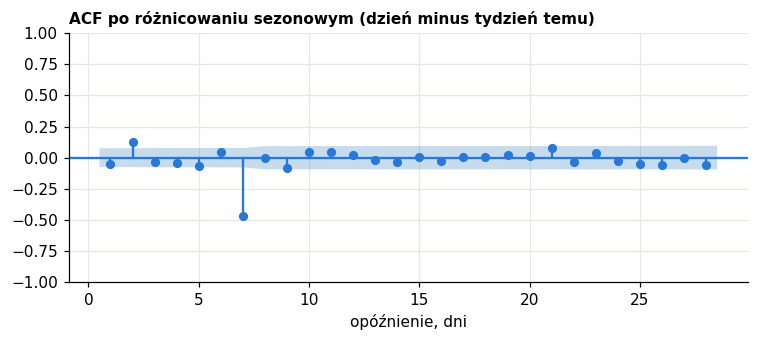

ACF różnic tygodniowych przy opóźnieniu 7: -0.470  -> sygnał zbyt silnego różnicowania


In [7]:
d7 = y_u.diff(S).dropna()
acf_d7 = acf(d7, nlags=LAGI_LB)
fig, ax = plt.subplots(figsize=(7, 3.2))
plot_acf(d7, lags=LAGI_LB, ax=ax, zero=False, color=NIEB, vlines_kwargs={"colors": NIEB})
ax.set_title("ACF po różnicowaniu sezonowym (dzień minus tydzień temu)", fontsize=10); ax.set_xlabel("opóźnienie, dni")
plt.tight_layout(); plt.show()
print(f"ACF różnic tygodniowych przy opóźnieniu 7: {acf_d7[S]:.3f}"
      + ("  -> sygnał zbyt silnego różnicowania" if acf_d7[S] < -0.35 else ""))

## 3. ARIMA: struktura i wybór modelu
Artykuł najpierw dopasowuje model sezonowy z różnicowaniem, a gdy sezonowa średnia ruchoma wychodzi na granicy (−1), przechodzi do regresji z trendem i zmiennymi sezonowymi, w której zależność w czasie modelują błędy ARMA. Potem porównuje kilku kandydatów kryteriami AIC i BIC i sprawdza wynik doboru automatycznego.

#### Objaśnienie: model sezonowy SARIMA(1,0,0)(0,1,1)₇
**Po co ta komórka.** Odtwarzamy pierwszy model z artykułu, tylko z okresem 7 zamiast 12: jeden człon AR, różnicowanie sezonowe i jeden sezonowy człon MA.

**Pojęcia.**
- **sma (sezonowa średnia ruchoma)**, w `statsmodels` `ma.S.L7`. Dopuszczalne wartości to przedział (−1, 1).
- **Współczynnik na granicy (−1)** oznacza, że model w części MA „cofa” różnicowanie sezonowe. Artykuł traktuje to jako znak, że różnicowanie sezonowe jest zbędne.
- **Dryf**: stały przyrost po różnicowaniu, czyli trend. W `SARIMAX` przy różnicowaniu uzyskujemy go przez `trend="t"`.

**Co robi kod.** `SARIMAX(y_u, order=(1, 0, 0), seasonal_order=(0, 1, 1, 7), trend="t")` z metodą największej wiarygodności (jak `arima()` w R), bez regresorów, ale z flagą dni zamkniętych (inaczej różnice tygodniowe wokół świąt byłyby ogromne). `res_sar.summary()` drukuje pełną tabelę.

**Jak czytać wynik.** Szukaj wiersza `ma.S.L7`. Wartość bliska −1 (np. poniżej −0,95): różnicowanie sezonowe zbędne, przechodzimy do regresji z błędami ARMA (kolejne komórki). Wyraźnie większa: model sezonowy jest rozsądną alternatywą.

In [8]:
mod_sar = SARIMAX(y_u, exog=X_u[["zamkniety"]], order=(1, 0, 0), seasonal_order=(0, 1, 1, S), trend="t")
res_sar = mod_sar.fit(disp=False, maxiter=300)
print(res_sar.summary().tables[1])
sma = res_sar.params.get("ma.S.L7", np.nan)
print(f"\nsma1 (ma.S.L7) = {sma:.3f}"
      + ("  -> na granicy: różnicowanie sezonowe zbędne, przechodzimy do regresji z błędami ARMA" if sma < -0.95
         else "  -> nie na granicy: model z różnicowaniem sezonowym też jest dopuszczalny"))

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
drift       2.686e-05      0.000      0.229      0.819      -0.000       0.000
zamkniety    -13.9799      0.327    -42.747      0.000     -14.621     -13.339
ar.L1          0.0872      0.044      1.982      0.048       0.001       0.173
ma.S.L7       -0.7756      0.044    -17.590      0.000      -0.862      -0.689
sigma2        10.9938      0.525     20.943      0.000       9.965      12.023

sma1 (ma.S.L7) = -0.776  -> nie na granicy: model z różnicowaniem sezonowym też jest dopuszczalny


#### Objaśnienie: zwykła regresja i jej reszty
**Po co ta komórka.** Zanim dodamy błędy ARMA, sprawdzamy, ile zależności zostaje po samej regresji (trend, dni tygodnia, miesiące, święta). To krok 22 z artykułu: zwykła regresja OLS, ACF reszt i test Ljunga–Boxa.

**Pojęcia.**
- **OLS** (metoda najmniejszych kwadratów) zakłada niezależne błędy. Gdy reszty są autokorelowane, współczynniki są nadal nieobciążone, ale ich **błędy standardowe są zaniżone**, więc przedziały ufności są zbyt wąskie. Artykuł podkreśla to jako częsty błąd.

**Co robi kod.** Dopasowuje OLS (`sm.OLS`), rysuje ACF i PACF reszt i liczy Ljunga–Boxa.

**Jak czytać wynik.** Istotny test (p < 0,05) i słupki poza granicami przy krótkich opóźnieniach (1, 2) oznaczają, że błędy trzeba modelować procesem ARMA. Kształt PACF reszt podpowiada rząd: wyraźne słupki przy 1 i 2, a potem cisza, sugerują AR(2).

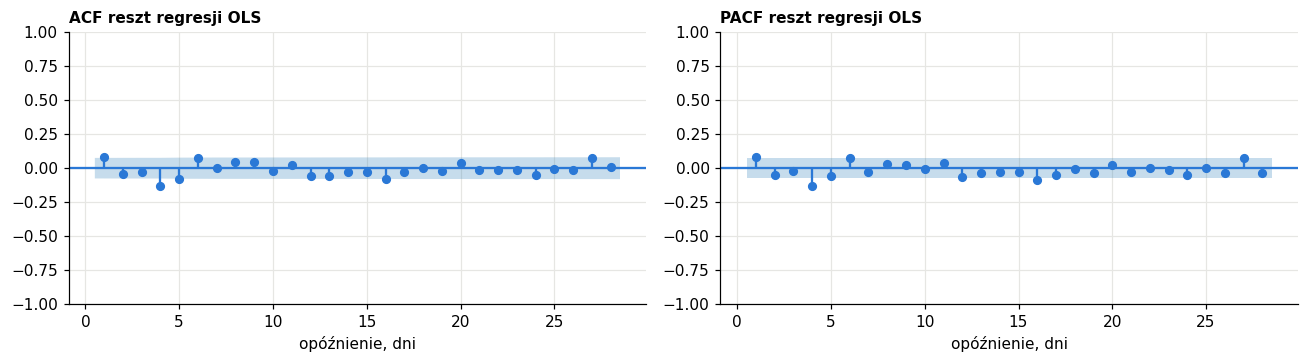

R² regresji: 0.940 | Ljung-Box reszt (28): p = 0.0147


In [9]:
ols = sm.OLS(y_u, X_u).fit()
fig, axs = plt.subplots(1, 2, figsize=(12, 3.4))
plot_acf(ols.resid, lags=LAGI_LB, ax=axs[0], zero=False, color=NIEB, vlines_kwargs={"colors": NIEB})
plot_pacf(ols.resid, lags=LAGI_LB, ax=axs[1], zero=False, method="ywm", color=NIEB, vlines_kwargs={"colors": NIEB})
axs[0].set_title("ACF reszt regresji OLS", fontsize=10); axs[1].set_title("PACF reszt regresji OLS", fontsize=10)
for a in axs: a.set_xlabel("opóźnienie, dni")
plt.tight_layout(); plt.show()
lb_ols = acorr_ljungbox(ols.resid, lags=[LAGI_LB])
print(f"R² regresji: {ols.rsquared:.3f} | Ljung-Box reszt ({LAGI_LB}): p = {lb_ols['lb_pvalue'].iloc[0]:.4f}")

#### Objaśnienie: kandydaci z artykułu i porównanie AIC/BIC
**Po co ta komórka.** Dopasowujemy tę samą regresję z pięcioma strukturami błędów z artykułu: ARMA(0,0), AR(1), AR(2), MA(1), ARMA(1,1). Porównanie AIC jest poprawne, bo część regresyjna i okres są we wszystkich modelach takie same.

**Pojęcia.**
- **ΔAIC**: różnica AIC względem najlepszego modelu. Orientacyjnie: poniżej 2 modele są praktycznie równorzędne, powyżej 10 gorszy model ma bardzo słabe poparcie.
- **`model_df` w Ljungu–Boxie** (w R `fitdf`): liczba oszacowanych parametrów ARMA. Odejmuje się ją od stopni swobody testu, bo dopasowane parametry same „zjadają” część autokorelacji.

**Co robi kod.**
- `dopasuj(p, q, P, Q)` dopasowuje `SARIMAX` z regresorami `X_u` i błędami ARMA(p,q), opcjonalnie z sezonowym AR/MA (P, Q) o okresie 7. Stała jest w `X_u`, więc `trend="n"`.
- Ljung–Box liczymy po pominięciu pierwszych 14 reszt (początkowe reszty filtru Kalmana są niestabilne).

**Jak czytać wynik.** Artykuł: wybierz najniższe AIC, ale zatwierdź dopiero po diagnostyce reszt. Model z najniższym AIC, którego reszty mają p Ljunga–Boxa < 0,05, nie jest jeszcze dobry. Wtedy wybierz bogatszy model, nawet przy niewielkiej różnicy AIC.

In [10]:
POMIN = 14     # pierwsze reszty filtru Kalmana pomijamy w diagnostyce

def dopasuj(p, q, P=0, Q=0):
    m = SARIMAX(y_u, exog=X_u, order=(p, 0, q), seasonal_order=(P, 0, Q, S), trend="n")
    r = m.fit(disp=False, maxiter=300)
    k = p + q + P + Q
    lb_ = acorr_ljungbox(r.resid.iloc[POMIN:], lags=[LAGI_LB], model_df=k)
    return r, {"model": f"ARMA({p},{q})" + (f"({P},0,{Q})7" if P or Q else ""), "p": p, "q": q, "P": P, "Q": Q,
               "AIC": r.aic, "BIC": r.bic, "LB_p": lb_["lb_pvalue"].iloc[0], "zbiezny": r.mle_retvals.get("converged", True)}

KANDYDACI = [(0, 0), (1, 0), (2, 0), (0, 1), (1, 1)]
modele, wiersze = {}, []
for p, q in KANDYDACI:
    r, w = dopasuj(p, q)
    modele[w["model"]] = r; wiersze.append(w)
tab_k = pd.DataFrame(wiersze).set_index("model")
tab_k["dAIC"] = tab_k["AIC"] - tab_k["AIC"].min()
print("Kandydaci z artykułu (regresja + błędy ARMA):")
print(tab_k[["AIC", "BIC", "dAIC", "LB_p", "zbiezny"]].round(3).to_string())

Kandydaci z artykułu (regresja + błędy ARMA):
                AIC       BIC   dAIC   LB_p  zbiezny
model                                               
ARMA(0,0)  2773.296  2881.578  3.355  0.012     True
ARMA(1,0)  2770.522  2883.316  0.581  0.040     True
ARMA(2,0)  2770.522  2887.827  0.581  0.031     True
ARMA(0,1)  2769.941  2882.735  0.000  0.044     True
ARMA(1,1)  2770.403  2887.708  0.462  0.038     True


#### Objaśnienie: dobór automatyczny (odpowiednik `auto.arima()`)
**Po co ta komórka.** Artykuł sprawdza, co wybierze `auto.arima()`. W Pythonie nie ma jej w `statsmodels`, więc robimy to samo jawnie: dopasowujemy wszystkie kombinacje rzędów z siatki i wybieramy najniższe AIC. Zaletą jest to, że widać wszystkie wyniki, a nie tylko zwycięzcę.

**Pojęcia.**
- **Sezonowe AR/MA (P, Q) bez różnicowania** (`seasonal_order=(P, 0, Q, 7)`) modelują zależność między tym samym dniem w kolejnych tygodniach, która mogła zostać po zmiennych dni tygodnia (np. gdy któryś tydzień jest ogólnie mocniejszy).

**Co robi kod.**
- Siatka: p, q od 0 do 2 i (P, Q) z {0, 1}, czyli 36 modeli. Każdy dopasowuje się kilka sekund, więc całość trwa kilka minut.
- `WYBOR` to reguła z artykułu: najniższe AIC wśród modeli z resztami bez zależności (p Ljunga–Boxa > 0,05) i z optymalizacją zakończoną sukcesem. Jeśli takiego nie ma, bierzemy najniższe AIC i drukujemy ostrzeżenie.
- Wyniki zapisujemy do `dane/interim/arima_porownanie_modeli.csv`.

**Jak czytać wynik.** Tabela 10 najlepszych modeli wg AIC z ΔAIC i p Ljunga–Boxa. Jeśli zwycięzca siatki to jeden z prostych kandydatów z poprzedniej komórki, wybór jest stabilny. Jeśli zwycięża model z członem sezonowym, w błędach został tygodniowy rytm, którego same zmienne dni tygodnia nie uchwyciły.

In [11]:
siatka = list(itertools.product(range(3), range(3), [0, 1], [0, 1]))
wiersze = []
for p, q, P, Q in siatka:
    try:
        r, w = dopasuj(p, q, P, Q)
    except Exception as e:                       # rzadkie problemy numeryczne: model pomijamy, ale odnotowujemy
        print(f"pominięto ARMA({p},{q})({P},0,{Q})7: {e}")
        continue
    modele[w["model"]] = r; wiersze.append(w)
tab_s = pd.DataFrame(wiersze).set_index("model").sort_values("AIC")
tab_s["dAIC"] = tab_s["AIC"] - tab_s["AIC"].min()
os.makedirs("dane/interim", exist_ok=True)
tab_s.reset_index().to_csv("dane/interim/arima_porownanie_modeli.csv", index=False)

dobre = tab_s[(tab_s["LB_p"] > 0.05) & tab_s["zbiezny"]]
if len(dobre):
    WYBOR = dobre.index[0]
else:
    WYBOR = tab_s.index[0]
    print("UWAGA: żaden model z siatki nie ma reszt bez zależności (Ljung-Box p > 0,05); biorę najniższe AIC")
print(f"Najniższe AIC w siatce: {tab_s.index[0]} | wybrany (najniższe AIC z czystymi resztami): {WYBOR}")
print(tab_s[["AIC", "BIC", "dAIC", "LB_p", "zbiezny"]].head(10).round(3).to_string())

Najniższe AIC w siatce: ARMA(1,2) | wybrany (najniższe AIC z czystymi resztami): ARMA(1,2)
                        AIC       BIC   dAIC   LB_p  zbiezny
model                                                       
ARMA(1,2)          2763.407  2885.224  0.000  0.108     True
ARMA(2,1)          2763.446  2885.263  0.039  0.115     True
ARMA(2,2)(0,0,1)7  2763.942  2894.783  0.536  0.203     True
ARMA(2,2)(1,0,0)7  2764.037  2894.877  0.630  0.204     True
ARMA(2,2)(1,0,1)7  2765.368  2900.721  1.962  0.138     True
ARMA(1,2)(0,0,1)7  2765.402  2891.731  1.996  0.086     True
ARMA(1,2)(1,0,0)7  2765.403  2891.732  1.996  0.086     True
ARMA(2,2)          2765.406  2891.735  1.999  0.085     True
ARMA(2,1)(0,0,1)7  2765.444  2891.773  2.037  0.091     True
ARMA(2,1)(1,0,0)7  2765.444  2891.773  2.037  0.091     True


## 4. Diagnostyka reszt wybranego modelu
Artykuł: test Ljunga–Boxa na resztach z `fitdf` równym liczbie parametrów ARMA oraz oszacowania współczynników z błędami standardowymi.

#### Objaśnienie: reszty i współczynniki wybranego modelu
**Po co ta komórka.** Zatwierdzamy model. Dobre reszty to biały szum: brak autokorelacji, średnia około 0, bez wyraźnych wzorów w czasie.

**Pojęcia.**
- **Błąd standardowy (SE)** współczynnika: niepewność oszacowania. Przedział 95 % to mniej więcej współczynnik ± 1,96 × SE.
- **Porównanie SE z OLS**: artykuł pokazuje, że przy autokorelacji OLS zaniża błędy standardowe. Kolumna `SE_OLS / SE_ARMA` poniżej 1 oznacza, że OLS byłby zbyt pewny siebie.

**Co robi kod.**
- Wykres reszt w czasie, ich histogram oraz ACF.
- Ljung–Box dla opóźnień 7, 14 i 28 z `model_df` = liczba parametrów ARMA.
- Tabela współczynników: części ARMA oraz najważniejszych regresorów (dni tygodnia, święta, trend), z błędami standardowymi z modelu ARMA i z OLS.

**Jak czytać wynik.**
- Komórka drukuje ostrzeżenie, gdy współczynnik MA jest na granicy (|ma| > 0,98) albo gdy `ar.L1` i `ma.L1` prawie się znoszą (np. 0,93 i −0,99). Model jest wtedy prawie równoważny prostszemu: AR i MA „wymazują się” nawzajem, a zostaje powolne dryfowanie poziomu. Artykuł traktuje współczynnik na granicy jako sygnał ostrzegawczy; wtedy porównaj go z prostszym kandydatem o czystych resztach.
- Reszty bez wzorów w czasie i ACF w granicach: model zatwierdzony. Pojedyncze duże reszty to zwykle dni nietypowe (np. promocja), których kalendarz nie zna.
- Współczynnik `t` to zmiana sprzedaży dziennej na rok (tys. zł), czyli trend.
- `dt_So` itd. to różnica dnia tygodnia względem poniedziałku; `przed_swietem`, `przed_bn`, `tydz_przed_wlk` to dodatkowa sprzedaż w tych dniach.

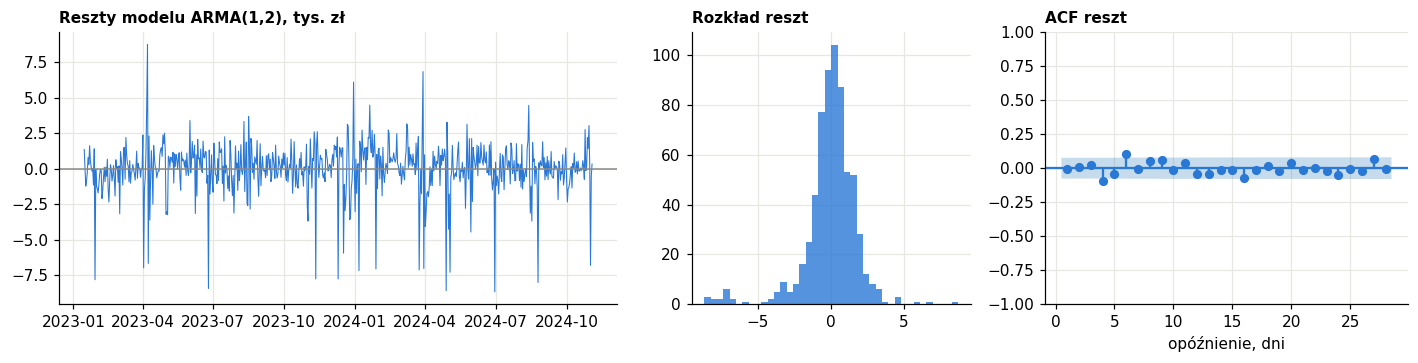

Ljung-Box reszt modelu ARMA(1,2) (model_df = 3):
            lb_stat  lb_pvalue
opóźnienia                    
7           15.0016     0.0047
14          23.1991     0.0166
28          33.9728     0.1085

Współczynniki (tys. zł; ar./ma. to część ARMA):
                wspolczynnik     SE      p  SE_OLS  SE_OLS / SE_ARMA
ar.L1                  0.870  0.064  0.000     NaN               NaN
ma.L1                 -0.787  0.078  0.000     NaN               NaN
ma.L2                 -0.147  0.044  0.001     NaN               NaN
t                      0.311  0.087  0.000   0.149             1.714
dt_Wt                  0.264  0.357  0.460   0.270             0.754
dt_Śr                  0.080  0.385  0.836   0.270             0.700
dt_Cz                  0.523  0.372  0.160   0.270             0.725
dt_Pt                  3.100  0.332  0.000   0.270             0.812
dt_So                  3.851  0.333  0.000   0.270             0.809
dt_Nd                 -4.584  0.315  0.000   0.411       

In [12]:
res = modele[WYBOR]
reszty = res.resid.iloc[POMIN:]
k_arma = int(tab_s.loc[WYBOR, ["p", "q", "P", "Q"]].sum())

fig, axs = plt.subplots(1, 3, figsize=(13, 3.4), gridspec_kw={"width_ratios": [2, 1, 1.3]})
axs[0].plot(reszty.index, reszty, color=NIEB, lw=0.7); axs[0].axhline(0, color=SZARY, lw=1)
axs[0].set_title(f"Reszty modelu {WYBOR}, tys. zł", fontsize=10)
axs[1].hist(reszty, bins=40, color=NIEB, alpha=0.8); axs[1].set_title("Rozkład reszt", fontsize=10)
plot_acf(reszty, lags=LAGI_LB, ax=axs[2], zero=False, color=NIEB, vlines_kwargs={"colors": NIEB})
axs[2].set_title("ACF reszt", fontsize=10); axs[2].set_xlabel("opóźnienie, dni")
plt.tight_layout(); plt.show()

lbw = acorr_ljungbox(reszty, lags=[7, 14, LAGI_LB], model_df=k_arma)
lbw.index.name = "opóźnienia"
print(f"Ljung-Box reszt modelu {WYBOR} (model_df = {k_arma}):")
print(lbw.round(4).to_string())

kol = [c for c in res.params.index if c.startswith(("ar.", "ma."))] + \
      [c for c in ["t"] + [f"dt_{d}" for d in DNI_TYG[1:]] + ["zamkniety", "przed_swietem", "tydz_przed_wlk", "przed_bn"]
       if c in res.params.index]
wsp = pd.DataFrame({"wspolczynnik": res.params[kol], "SE": res.bse[kol], "p": res.pvalues[kol]})
wsp["SE_OLS"] = ols.bse.reindex(kol)
wsp["SE_OLS / SE_ARMA"] = wsp["SE_OLS"] / wsp["SE"]
print("\nWspółczynniki (tys. zł; ar./ma. to część ARMA):")
print(wsp.round(3).to_string())

# Sygnały ostrzegawcze z artykułu: współczynnik MA na granicy (-1) oraz AR i MA, które się prawie znoszą
ma_gr = [c for c in res.params.index if c.startswith("ma.") and abs(res.params[c]) > 0.98]
if ma_gr:
    print(f"\nUWAGA: współczynnik MA na granicy dopuszczalnych wartości: {ma_gr}.")
if "ar.L1" in res.params and "ma.L1" in res.params and abs(res.params["ar.L1"] + res.params["ma.L1"]) < 0.1:
    print(f"UWAGA: ar.L1 = {res.params['ar.L1']:.3f} i ma.L1 = {res.params['ma.L1']:.3f} prawie się znoszą. "
          "Błędy są wtedy bliskie białemu szumowi z powolnym dryfem poziomu; prostszy model z tabeli kandydatów "
          "(np. ARMA(0,0) albo AR(1)) może być równie dobry, jeśli ma czyste reszty i bliskie AIC.")

## 5. Prognoza i jej ocena
Artykuł prognozuje z modelu dopasowanego tylko do okresu wcześniejszego, z przedziałem predykcji 95 %, i liczy obserwacje poza przedziałem. Tu dodatkowo porównujemy trafność z dwoma prostymi punktami odniesienia z notatnika głównego.

#### Objaśnienie: prognoza 8 tygodni naprzód z przedziałem 95 %
**Po co ta komórka.** Sprawdzamy model na dniach, których nie widział (od 2024-11-04 do końca roku).

**Pojęcia.**
- **Prognoza wielokrokowa**: model zna dane tylko do 3.11.2024 i prognozuje wszystkie kolejne dni naraz. Tak robi artykuł (36 miesięcy naprzód).
- **Prognoza krocząca na tydzień naprzód**: po każdym tygodniu model dostaje prawdziwe dane z tego tygodnia (bez ponownego szacowania parametrów) i prognozuje kolejny tydzień. Tak działa prognoza w praktyce i tak działają `Tydzien_temu` oraz `Srednia_4_tygodni`, więc tylko ta wersja jest uczciwie porównywalna z nimi.
- **Pokrycie przedziału**: odsetek dni, w których prawdziwa sprzedaż leży w przedziale 95 %. Około 95 % oznacza dobrze skalibrowany model; dużo mniej oznacza zbyt wąski przedział (model zbyt pewny siebie).

**Co robi kod.**
- `res.get_forecast(..., exog=X_w)` liczy prognozę wielokrokową i przedział. Regresory dla przyszłych dni bierzemy z kalendarza (w R: `newxreg`).
- Prognoza krocząca: dla każdego poniedziałku okresu sprawdzającego budujemy model na danych do poprzedzającej niedzieli, `filter(res.params)` przelicza stan modelu z ustalonymi parametrami (bez ponownego szacowania) i prognozujemy 7 dni.
- Punkty odniesienia jak w notatniku głównym: `Tydzien_temu` to sprzedaż sprzed 7 dni, `Srednia_4_tygodni` to średnia tego samego dnia tygodnia z 4 poprzednich tygodni (dni zamknięte pomijane).
- Oceniamy tylko dni otwarte, na których wszystkie metody mają prognozę.

**Jak czytać wynik.**
- Wykres: szare pasmo to przedział 95 % prognozy wielokrokowej. Punkty poza pasmem to dni, których model się nie spodziewał.
- Szerokość przedziału na początku i na końcu: artykuł zwraca uwagę, że rośnie z horyzontem.
- Tabela WAPE: jeśli ARIMA krocząca nie bije `Srednia_4_tygodni`, model nie wnosi nic ponad prostą średnią i do prognoz wystarczy punkt odniesienia. Okres sprawdzający obejmuje grudzień, więc wynik mocno zależy od świąt; tabela pokazuje też wynik bez 18–31 grudnia.

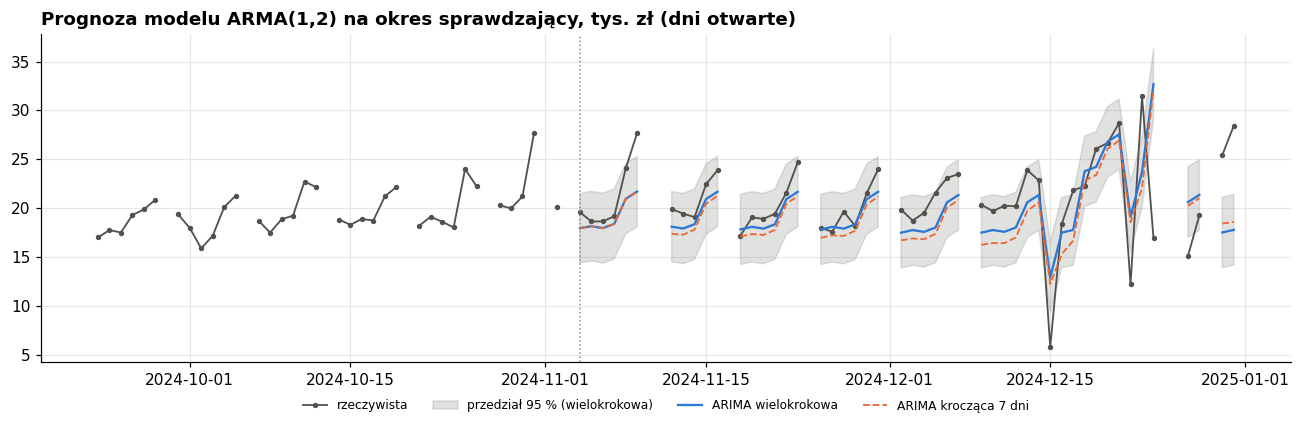

Dni otwarte poza przedziałem 95 %: 9 z 49 (pokrycie 81.6 %)
Szerokość przedziału: pierwszy dzień 7.1, ostatni dzień 7.2 tys. zł

Trafność na dniach otwartych okresu sprawdzającego:
                    WAPE_% wszystkie dni  WAPE_% bez 18-31.12
ARIMA_wielokrokowa                 12.67                 8.62
ARIMA_kroczaca_7d                  14.86                11.70
Tydzien_temu                       13.72                 7.53
Srednia_4_tygodni                  11.26                 6.13


In [13]:
# Prognoza wielokrokowa (jak w artykule)
fc = res.get_forecast(steps=len(y_w), exog=X_w).summary_frame(alpha=0.05)
fc.index = y_w.index

# Prognoza krocząca na tydzień naprzód, parametry stałe (z okresu uczącego)
p_, q_, P_, Q_ = (int(tab_s.loc[WYBOR, c]) for c in ["p", "q", "P", "Q"])
krok = []
for pon in pd.date_range(WALID_OD, KONIEC, freq="7D"):
    hist = dni < pon
    m_k = SARIMAX(y[hist], exog=X[hist], order=(p_, 0, q_), seasonal_order=(P_, 0, Q_, S), trend="n")
    r_k = m_k.filter(res.params)
    dalej = (dni >= pon) & (dni < pon + pd.Timedelta(days=7))
    f_k = r_k.get_forecast(steps=int(dalej.sum()), exog=X[dalej]).predicted_mean
    f_k.index = dni[dalej]
    krok.append(f_k)
krok = pd.concat(krok)

# Punkty odniesienia z notatnika głównego (dni zamknięte = brak, nie zero)
s_h = y.where(zamk == 0)
tydz_temu = s_h.shift(7)
sr4 = pd.concat([s_h.shift(7 * k) for k in (1, 2, 3, 4)], axis=1).mean(axis=1)

tab = pd.DataFrame({"rzeczywista": y_w, "ARIMA_wielokrokowa": fc["mean"], "ARIMA_kroczaca_7d": krok,
                    "Tydzien_temu": tydz_temu[~uczacy], "Srednia_4_tygodni": sr4[~uczacy]})
tab = tab[(zamk[~uczacy] == 0)].dropna()
wape = lambda t, k: (t[k] - t["rzeczywista"]).abs().sum() / t["rzeczywista"].sum() * 100
bez_sw = tab[~((tab.index.month == 12) & (tab.index.day >= 18))]
metody = ["ARIMA_wielokrokowa", "ARIMA_kroczaca_7d", "Tydzien_temu", "Srednia_4_tygodni"]
oc = pd.DataFrame({"WAPE_% wszystkie dni": [wape(tab, m) for m in metody],
                   "WAPE_% bez 18-31.12": [wape(bez_sw, m) for m in metody]}, index=metody)

otw_w = zamk[~uczacy] == 0
poza = ((y_w < fc["mean_ci_lower"]) | (y_w > fc["mean_ci_upper"]))[otw_w]
szer = (fc["mean_ci_upper"] - fc["mean_ci_lower"])[otw_w]

fig, ax = plt.subplots(figsize=(12, 4))
ost = y.index >= WALID_OD - pd.Timedelta(days=42)
ax.plot(y.index[ost], y.where(zamk == 0)[ost], color="#52514e", lw=1.2, marker="o", ms=2.5, label="rzeczywista")
ax.fill_between(fc.index, fc["mean_ci_lower"], fc["mean_ci_upper"], where=otw_w.values, color=SZARY, alpha=0.25, label="przedział 95 % (wielokrokowa)")
ax.plot(fc.index, fc["mean"].where(otw_w), color=NIEB, lw=1.5, label="ARIMA wielokrokowa")
ax.plot(krok.index, krok.where(otw_w), color=POM, lw=1.2, ls="--", label="ARIMA krocząca 7 dni")
ax.axvline(WALID_OD, color=SZARY, lw=1, ls=":")
ax.set_title(f"Prognoza modelu {WYBOR} na okres sprawdzający, tys. zł (dni otwarte)")
ax.legend(frameon=False, fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.08))
plt.tight_layout(); plt.show()

print(f"Dni otwarte poza przedziałem 95 %: {int(poza.sum())} z {len(poza)} (pokrycie {100 * (1 - poza.mean()):.1f} %)")
print(f"Szerokość przedziału: pierwszy dzień {szer.iloc[0]:.1f}, ostatni dzień {szer.iloc[-1]:.1f} tys. zł")
print("\nTrafność na dniach otwartych okresu sprawdzającego:")
print(oc.round(2).to_string())

## 6. Raport (krok 7 z artykułu)
Artykuł zaleca opisać: okres i częstotliwość danych, sposób uwzględnienia trendu i sezonowości, strukturę błędów, diagnostykę reszt i prognozę. Poniższa komórka składa to automatycznie z wyników.

#### Objaśnienie: podsumowanie liczbowe
**Po co ta komórka.** Zbiera najważniejsze liczby z całego notatnika w kilku zdaniach, gotowych do skopiowania do opisu analizy. Po zmianie danych zaktualizują się same.

**Jak czytać wynik.** Każda linijka odpowiada jednemu punktowi raportu z artykułu. Ostatnia mówi wprost, czy ARIMA jest lepsza od najlepszego prostego punktu odniesienia.

In [14]:
naj_prosty = oc.loc[["Tydzien_temu", "Srednia_4_tygodni"], "WAPE_% wszystkie dni"].idxmin()
print("RAPORT")
print(f"- Dane: sprzedaż dzienna sklepu (tys. zł), {POCZ.date()} … {KONIEC.date()}, {len(y)} dni; "
      f"uczenie do {(WALID_OD - pd.Timedelta(days=1)).date()}, sprawdzenie {WALID_OD.date()} … {KONIEC.date()}. Rok 2025 poza analizą.")
print(f"- Sezonowość: tygodniowa (dni tygodnia) i roczna (miesiące) jako zmienne zero-jedynkowe; trend liniowy "
      f"({res.params.get('t', np.nan):+.2f} tys. zł dziennie na rok); dni zamknięte i okolice świąt jako regresory.")
print(f"- Różnicowanie sezonowe: sma1 = {sma:.3f}, ACF różnic tygodniowych przy 7 = {acf_d7[S]:.3f}.")
print(f"- Struktura błędów: {WYBOR} (AIC {tab_s.loc[WYBOR, 'AIC']:.1f}, ΔAIC {tab_s.loc[WYBOR, 'dAIC']:.1f} względem najlepszego w siatce).")
print(f"- Diagnostyka: Ljung-Box reszt ({LAGI_LB} opóźnień, model_df = {k_arma}) p = {lbw.loc[LAGI_LB, 'lb_pvalue']:.3f}; "
      f"OLS bez ARMA: p = {lb_ols['lb_pvalue'].iloc[0]:.4f}.")
print(f"- Prognoza: pokrycie przedziału 95 % = {100 * (1 - poza.mean()):.1f} % dni otwartych; "
      f"WAPE wielokrokowa {oc.loc['ARIMA_wielokrokowa'].iloc[0]:.1f} %, krocząca {oc.loc['ARIMA_kroczaca_7d'].iloc[0]:.1f} %, "
      f"{naj_prosty} {oc.loc[naj_prosty].iloc[0]:.1f} %.")
lepsza = oc.loc["ARIMA_kroczaca_7d"].iloc[0] < oc.loc[naj_prosty].iloc[0]
print(f"- Wniosek: ARIMA krocząca {'jest lepsza' if lepsza else 'NIE jest lepsza'} od najlepszego prostego punktu odniesienia ({naj_prosty}).")

RAPORT
- Dane: sprzedaż dzienna sklepu (tys. zł), 2023-01-01 … 2024-12-31, 731 dni; uczenie do 2024-11-03, sprawdzenie 2024-11-04 … 2024-12-31. Rok 2025 poza analizą.
- Sezonowość: tygodniowa (dni tygodnia) i roczna (miesiące) jako zmienne zero-jedynkowe; trend liniowy (+0.31 tys. zł dziennie na rok); dni zamknięte i okolice świąt jako regresory.
- Różnicowanie sezonowe: sma1 = -0.776, ACF różnic tygodniowych przy 7 = -0.470.
- Struktura błędów: ARMA(1,2) (AIC 2763.4, ΔAIC 0.0 względem najlepszego w siatce).
- Diagnostyka: Ljung-Box reszt (28 opóźnień, model_df = 3) p = 0.108; OLS bez ARMA: p = 0.0147.
- Prognoza: pokrycie przedziału 95 % = 81.6 % dni otwartych; WAPE wielokrokowa 12.7 %, krocząca 14.9 %, Srednia_4_tygodni 11.3 %.
- Wniosek: ARIMA krocząca NIE jest lepsza od najlepszego prostego punktu odniesienia (Srednia_4_tygodni).
